In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [34]:
# Ganti 'data_clean.xlsx' dengan nama file kamu
df = pd.read_excel('dataset/data_clean.xlsx', sheet_name='surya_kaleng')

# Pastikan format tanggal
df['ds'] = pd.to_datetime(df['ds'])
df = df.sort_values('ds')
# Handling hari libur/kosong
df.loc[df['y'] == 0, 'y'] = np.nan 

print(f"Data tersedia dari {df['ds'].min().date()} sampai {df['ds'].max().date()}")

Data tersedia dari 2023-01-01 sampai 2025-12-31


In [36]:
# 1. TRAIN: Januari 2023 - Desember 2024
train_data = df[(df['ds'] >= '2023-01-01') & (df['ds'] <= '2024-12-31')].copy()

# 2. TEST (Target Prediksi): 1 - 14 Januari 2025
test_data = df[df['ds'] >= '2025-01-01'].copy()

print(f"Data Train: {len(train_data)} hari")
print(f"Data Test: {len(test_data)} hari")

Data Train: 727 hari
Data Test: 365 hari


In [37]:
# Inisialisasi model (gunakan skala terbaikmu)
model = Prophet(
    changepoint_prior_scale=0.1,
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False
)

# Fit model hanya pada data train
model.fit(train_data)

# Prediksi untuk 14 hari ke depan (Januari 2025)
future = model.make_future_dataframe(periods=14, freq='D')
forecast = model.predict(future)

# Ambil hasil prediksi Januari 2025
forecast_jan = forecast[forecast['ds'] >= '2025-01-01'].copy()

18:05:14 - cmdstanpy - INFO - Chain [1] start processing
18:05:14 - cmdstanpy - INFO - Chain [1] done processing


In [38]:
# Gabungkan hasil untuk evaluasi MAE
evaluation = forecast_jan.merge(test_data[['ds', 'y']], on='ds')

# Hitung error
mae = mean_absolute_error(evaluation['y'], evaluation['yhat'])
kebutuhan_stok = round(evaluation['yhat'].sum())
safety_stock = round(mae * 14) # Lead time 14 hari

print("--- HASIL PENGUJIAN JANUARI 2025 ---")
print("Kebutuhan stok 14 hari :", kebutuhan_stok)
print("Safety Stock           :", safety_stock)
print("Rekomendasi Pembelian  :", kebutuhan_stok + safety_stock)
print(f"MAE                    : {mae:.0f}")

--- HASIL PENGUJIAN JANUARI 2025 ---
Kebutuhan stok 14 hari : 2106
Safety Stock           : 333
Rekomendasi Pembelian  : 2439
MAE                    : 24


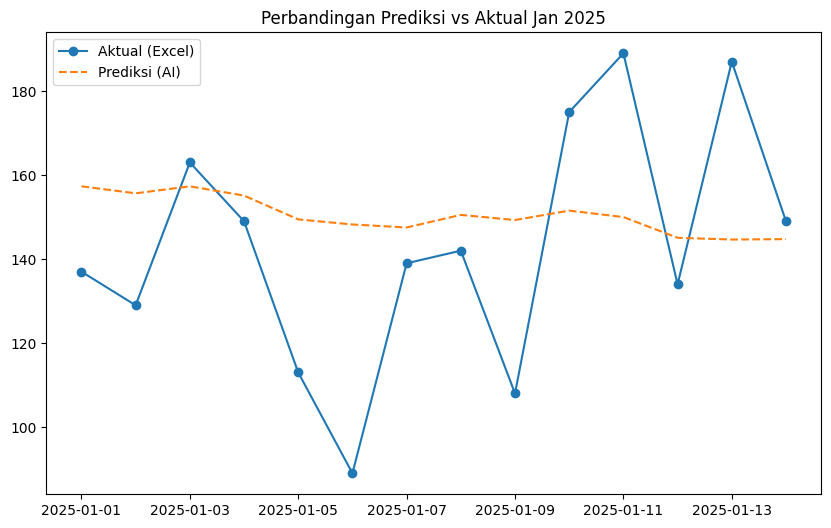

In [ ]:
plt.figure(figsize=(10,6))
plt.plot(evaluation['ds'], evaluation['y'], label='Aktual (Excel)', marker='o')
plt.plot(evaluation['ds'], evaluation['yhat'], label='Prediksi (AI)', linestyle='--')
plt.legend()
plt.title('Perbandingan Prediksi vs Aktual Jan 2025')
plt.show()